In [1]:
from google.colab import files

uploaded = files.upload()

Saving match_info.zip to match_info.zip
Saving ball_by_ball_ipl.zip to ball_by_ball_ipl.zip


In [2]:
import zipfile
import os

# Extract match information
with zipfile.ZipFile('match_info.zip', 'r') as zip_ref:
    zip_ref.extractall()

# Extract ball-by-ball IPL data
with zipfile.ZipFile('ball_by_ball_ipl.zip', 'r') as zip_ref:
    zip_ref.extractall()

print(os.listdir())

['.config', 'ball_by_ball_ipl.zip', 'match_info.zip', 'match_info.csv', 'ball_by_ball_ipl.csv', 'sample_data']


In [6]:
import pandas as pd

# Load the datasets with low_memory=False to avoid DtypeWarning
matches = pd.read_csv('match_info.csv', low_memory=False)
deliveries = pd.read_csv('ball_by_ball_ipl.csv', low_memory=False)

# Check dataset size
print("Match Info dataset shape:", matches.shape)
print("Ball-by-Ball dataset shape:", deliveries.shape)

Match Info dataset shape: (11252, 45)
Ball-by-Ball dataset shape: (295732, 32)


In [7]:
print("MATCH INFO COLUMNS:\n")
print(matches.columns.tolist())

print("\n" + "="*80)

print("\nBALL-BY-BALL COLUMNS:\n")
print(deliveries.columns.tolist())

MATCH INFO COLUMNS:

['match_id', 'match_type', 'team1', 'team2', 'team1_icc_type', 'team2_icc_type', 'gender', 'season', 'start_date', 'venue', 'city', 'event', 'match_number', 'toss_winner', 'toss_decision', 'winner', 'winner_runs', 'winner_wickets', 'player_of_match1', 'umpire1', 'umpire2', 'tv_umpire1', 'reserve_umpire1', 'match_referee', 'outcome', 'method', 'eliminator', 'bowl_out', 'winner_innings', 'super_over', 'declared', 'overs', 'target_overs', 'target_runs', 'match_type_number', 'team_type', 'balls_per_over', 'toss_uncontested', 'player_of_match2', 'umpire3', 'umpire4', 'tv_umpire2', 'reserve_umpire2', 'end_date', 'match_dates']


BALL-BY-BALL COLUMNS:

['match_id', 'season', 'start_date', 'venue', 'innings', 'ball', 'batting_team', 'bowling_team', 'striker', 'non_striker', 'bowler', 'runs_off_bat', 'extras', 'wides', 'noballs', 'byes', 'legbyes', 'penalty', 'wicket_type', 'player_dismissed', 'other_wicket_type', 'other_player_dismissed', 'match_type', 'over_no', 'delivery

In [8]:
print("MATCH TYPES IN MATCH INFO:")
print(matches['match_type'].value_counts())

print("\nMATCH TYPES IN BALL-BY-BALL DATA:")
print(deliveries['match_type'].value_counts())


MATCH TYPES IN MATCH INFO:
match_type
T20     5849
ODI     3237
IPL     1243
TEST     923
Name: count, dtype: int64

MATCH TYPES IN BALL-BY-BALL DATA:
match_type
IPL    295732
Name: count, dtype: int64


In [9]:
# Filter only IPL matches
ipl_matches = matches[matches['match_type'] == 'IPL'].copy()

# Check the result
print("Original match records:", matches.shape[0])
print("IPL match records:", ipl_matches.shape[0])

# Display first 5 IPL records
display(ipl_matches.head())

Original match records: 11252
IPL match records: 1243


,match_id,match_type,team1,team2,team1_icc_type,team2_icc_type,gender,season,start_date,venue,...,team_type,balls_per_over,toss_uncontested,player_of_match2,umpire3,umpire4,tv_umpire2,reserve_umpire2,end_date,match_dates
10009,1082591,IPL,Sunrisers Hyderabad,Royal Challengers Bangalore,NaN,NaN,male,2017,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",...,club,6,NaN,NaN,NaN,NaN,NaN,NaN,2017-04-05,2017/04/05
10010,1082592,IPL,Rising Pune Supergiant,Mumbai Indians,NaN,NaN,male,2017,2017-04-06,"Maharashtra Cricket Association Stadium, Pune",...,club,6,NaN,NaN,NaN,NaN,NaN,NaN,2017-04-06,2017/04/06
10011,1082593,IPL,Gujarat Lions,Kolkata Knight Riders,NaN,NaN,male,2017,2017-04-07,"Saurashtra Cricket Association Stadium, Rajkot",...,club,6,NaN,NaN,NaN,NaN,NaN,NaN,2017-04-07,2017/04/07
10012,1082594,IPL,Kings XI Punjab,Rising Pune Supergiant,NaN,NaN,male,2017,2017-04-08,"Holkar Cricket Stadium, Indore",...,club,6,NaN,NaN,NaN,NaN,NaN,NaN,2017-04-08,2017/04/08
10013,1082595,IPL,Royal Challengers Bangalore,Delhi Daredevils,NaN,NaN,male,2017,2017-04-08,"M Chinnaswamy Stadium, Bengaluru",...,club,6,NaN,NaN,NaN,NaN,NaN,NaN,2017-04-08,2017/04/08


In [11]:
# Check missing values in IPL match data
print("Missing values in IPL Matches:")
print(ipl_matches.isnull().sum()[ipl_matches.isnull().sum() > 0])

print("\n" + "="*60)

# Check missing values in ball-by-ball data
print("\nMissing values in Ball-by-Ball Data:")
print(deliveries.isnull().sum()[deliveries.isnull().sum() > 0])

print("\n" + "="*60)

# Check duplicate records
print("\nDuplicate records:")
print("IPL Matches:", ipl_matches.duplicated().sum())
print("Ball-by-Ball:", deliveries.duplicated().sum())

Missing values in IPL Matches:
team1_icc_type       1243
team2_icc_type       1243
city                   51
match_number           74
winner                 25
winner_runs           685
winner_wickets        583
player_of_match1        9
tv_umpire1              4
reserve_umpire1        24
outcome              1218
method               1220
eliminator           1227
bowl_out             1243
winner_innings       1243
super_over           1227
declared             1243
target_overs            6
target_runs             6
match_type_number    1243
toss_uncontested     1243
player_of_match2     1243
umpire3              1243
umpire4              1243
tv_umpire2           1243
reserve_umpire2      1243
dtype: int64


Missing values in Ball-by-Ball Data:
wides                     285856
noballs                   294506
byes                      294987
legbyes                   291326
penalty                   295730
wicket_type               281027
player_dismissed          281027
other_wick

In [12]:
# Select important columns for IPL analysis
ipl_matches_clean = ipl_matches[[
    'match_id',
    'season',
    'start_date',
    'team1',
    'team2',
    'winner',
    'venue',
    'player_of_match1'
]].copy()

# Convert date column to datetime format
ipl_matches_clean['start_date'] = pd.to_datetime(
    ipl_matches_clean['start_date']
)

# Standardize season using the match year
ipl_matches_clean['season_year'] = (
    ipl_matches_clean['start_date'].dt.year
)

# Check missing values in the cleaned dataset
print("Missing values after selecting important columns:")
print(ipl_matches_clean.isnull().sum())

display(ipl_matches_clean.head())

Missing values after selecting important columns:
match_id             0
season               0
start_date           0
team1                0
team2                0
winner              25
venue                0
player_of_match1     9
season_year          0
dtype: int64


,match_id,season,start_date,team1,team2,winner,venue,player_of_match1,season_year
10009,1082591,2017,2017-04-05,Sunrisers Hyderabad,Royal Challengers Bangalore,Sunrisers Hyderabad,"Rajiv Gandhi International Stadium, Uppal",Yuvraj Singh,2017
10010,1082592,2017,2017-04-06,Rising Pune Supergiant,Mumbai Indians,Rising Pune Supergiant,"Maharashtra Cricket Association Stadium, Pune",SPD Smith,2017
10011,1082593,2017,2017-04-07,Gujarat Lions,Kolkata Knight Riders,Kolkata Knight Riders,"Saurashtra Cricket Association Stadium, Rajkot",CA Lynn,2017
10012,1082594,2017,2017-04-08,Kings XI Punjab,Rising Pune Supergiant,Kings XI Punjab,"Holkar Cricket Stadium, Indore",GJ Maxwell,2017
10013,1082595,2017,2017-04-08,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,"M Chinnaswamy Stadium, Bengaluru",KM Jadhav,2017


In [13]:
# Create a copy of the ball-by-ball dataset
ipl_deliveries_clean = deliveries.copy()

# Fill missing values in extra-related columns with 0
extra_columns = [
    'wides',
    'noballs',
    'byes',
    'legbyes',
    'penalty'
]

ipl_deliveries_clean[extra_columns] = (
    ipl_deliveries_clean[extra_columns].fillna(0)
)

# Check important columns for missing values
print("Missing values in important columns:")
print(
    ipl_deliveries_clean[
        ['match_id', 'striker', 'bowler', 'runs_off_bat']
    ].isnull().sum()
)

print("\nClean dataset shape:", ipl_deliveries_clean.shape)

Missing values in important columns:
match_id        0
striker         0
bowler          0
runs_off_bat    0
dtype: int64

Clean dataset shape: (295732, 32)


In [15]:
# Exclude wide deliveries when calculating balls faced
legal_balls_for_batting = ipl_deliveries_clean[
    ipl_deliveries_clean['wides'] == 0
].copy()

# Calculate accurate batting statistics
batting_stats = (
    legal_balls_for_batting
    .groupby('striker')
    .agg(
        Total_Runs=('runs_off_bat', 'sum'),
        Balls_Faced=('runs_off_bat', 'count')
    )
    .reset_index()
)

# Calculate strike rate
batting_stats['Strike_Rate'] = (
    batting_stats['Total_Runs'] / batting_stats['Balls_Faced'] * 100
).round(2)

# Sort by total runs
batting_stats = batting_stats.sort_values(
    by='Total_Runs',
    ascending=False
)

# Top 10 batters
top_10_batters = batting_stats.head(10)

print("Top 10 IPL Run Scorers (2008–2026)")
display(top_10_batters)

Top 10 IPL Run Scorers (2008–2026)


,striker,Total_Runs,Balls_Faced,Strike_Rate
694,V Kohli,9346,6930,134.86
527,RG Sharma,7331,5517,132.88
564,S Dhawan,6769,5326,127.09
159,DA Warner,6567,4702,139.66
311,KL Rahul,5828,4188,139.16
598,SK Raina,5536,4046,136.83
409,MS Dhoni,5439,3957,137.45
52,AM Rahane,5367,4273,125.60
628,SV Samson,5181,3671,141.13
31,AB de Villiers,5181,3411,151.89


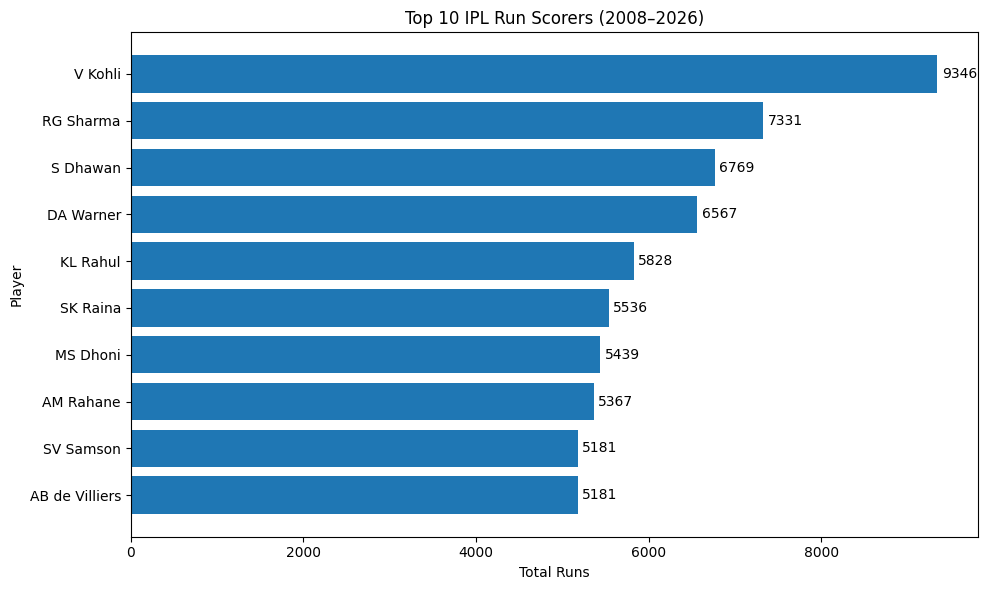

In [16]:
import matplotlib.pyplot as plt

# Sort top 10 batters for better horizontal chart visualization
chart_data = top_10_batters.sort_values(
    by='Total_Runs',
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    chart_data['striker'],
    chart_data['Total_Runs']
)

plt.xlabel('Total Runs')
plt.ylabel('Player')
plt.title('Top 10 IPL Run Scorers (2008–2026)')

# Add run values to each bar
for index, value in enumerate(chart_data['Total_Runs']):
    plt.text(value + 50, index, str(value), va='center')

plt.tight_layout()
plt.show()

In [17]:
# Dismissals that should NOT be credited to the bowler
non_bowler_wickets = [
    'run out',
    'retired hurt',
    'obstructing the field'
]

# Filter valid bowler wickets
bowler_wickets = ipl_deliveries_clean[
    ipl_deliveries_clean['wicket_type'].notna() &
    ~ipl_deliveries_clean['wicket_type'].isin(non_bowler_wickets)
].copy()

# Calculate wickets for each bowler
bowling_stats = (
    bowler_wickets
    .groupby('bowler')
    .size()
    .reset_index(name='Wickets')
    .sort_values(by='Wickets', ascending=False)
)

# Display Top 10 wicket takers
top_10_bowlers = bowling_stats.head(10)

print("Top 10 IPL Wicket Takers (2008–2026)")
display(top_10_bowlers)

Top 10 IPL Wicket Takers (2008–2026)


,bowler,Wickets
485,YS Chahal,233
65,B Kumar,226
411,SP Narine,209
323,PP Chawla,192
187,JJ Bumrah,190
333,R Ashwin,187
113,DJ Bravo,183
349,RA Jadeja,180
369,Rashid Khan,179
7,A Mishra,174


In [18]:
# Calculate runs conceded by each bowler
ipl_deliveries_clean['runs_conceded'] = (
    ipl_deliveries_clean['runs_off_bat'] +
    ipl_deliveries_clean['wides'] +
    ipl_deliveries_clean['noballs']
)

# Legal balls bowled (wides and no-balls are not legal deliveries)
legal_deliveries = ipl_deliveries_clean[
    (ipl_deliveries_clean['wides'] == 0) &
    (ipl_deliveries_clean['noballs'] == 0)
].copy()

# Calculate bowling statistics
bowling_performance = (
    ipl_deliveries_clean
    .groupby('bowler')
    .agg(
        Runs_Conceded=('runs_conceded', 'sum')
    )
    .reset_index()
)

# Calculate legal balls bowled
balls_bowled = (
    legal_deliveries
    .groupby('bowler')
    .size()
    .reset_index(name='Balls_Bowled')
)

# Merge runs and balls
bowling_performance = bowling_performance.merge(
    balls_bowled,
    on='bowler'
)

# Calculate overs and economy rate
bowling_performance['Overs_Bowled'] = (
    bowling_performance['Balls_Bowled'] / 6
)

bowling_performance['Economy_Rate'] = (
    bowling_performance['Runs_Conceded'] /
    bowling_performance['Overs_Bowled']
).round(2)

# Add wickets to the bowling performance table
bowling_performance = bowling_performance.merge(
    bowling_stats,
    on='bowler',
    how='left'
)

# Bowlers with no wickets get 0
bowling_performance['Wickets'] = (
    bowling_performance['Wickets'].fillna(0).astype(int)
)

# Show the Top 10 wicket takers with economy rate
top_bowler_performance = (
    bowling_performance
    .sort_values('Wickets', ascending=False)
    .head(10)
)

print("Top 10 IPL Bowlers - Wickets and Economy (2008–2026)")
display(
    top_bowler_performance[
        ['bowler', 'Wickets', 'Runs_Conceded',
         'Overs_Bowled', 'Economy_Rate']
    ]
)

Top 10 IPL Bowlers - Wickets and Economy (2008–2026)


,bowler,Wickets,Runs_Conceded,Overs_Bowled,Economy_Rate
570,YS Chahal,233,5417.0,672.833333,8.05
76,B Kumar,226,5913.0,766.666667,7.71
481,SP Narine,209,5273.0,776.666667,6.79
375,PP Chawla,192,5108.0,641.666667,7.96
214,JJ Bumrah,190,4469.0,608.833333,7.34
387,R Ashwin,187,5652.0,785.000000,7.20
131,DJ Bravo,183,4360.0,520.000000,8.38
406,RA Jadeja,180,5465.0,709.000000,7.71
433,Rashid Khan,179,4297.0,590.500000,7.28
8,A Mishra,174,4145.0,561.833333,7.38


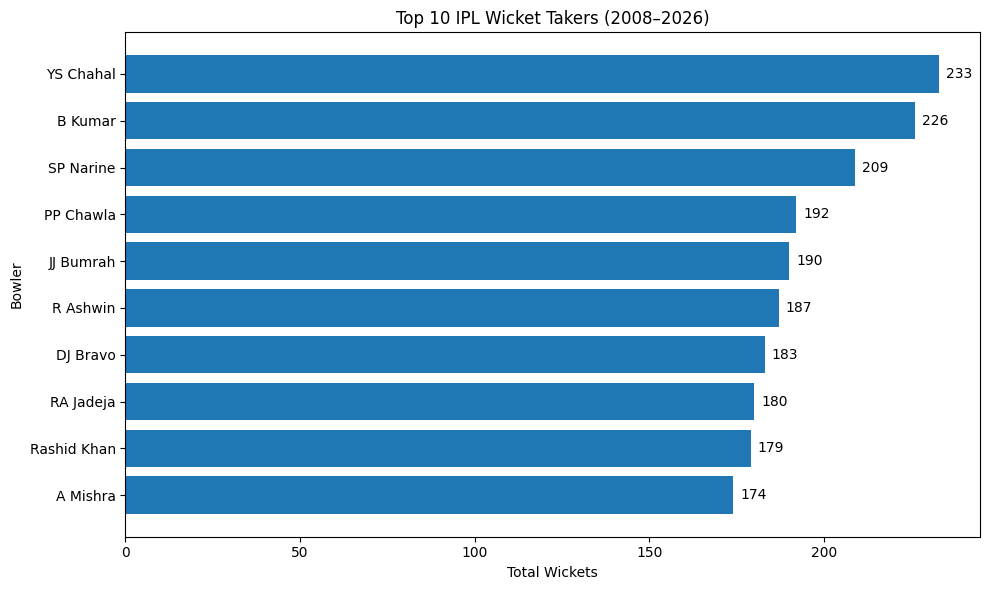

In [19]:
import matplotlib.pyplot as plt

# Sort for horizontal bar chart
chart_bowlers = top_10_bowlers.sort_values(
    by='Wickets',
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    chart_bowlers['bowler'],
    chart_bowlers['Wickets']
)

plt.xlabel('Total Wickets')
plt.ylabel('Bowler')
plt.title('Top 10 IPL Wicket Takers (2008–2026)')

# Add wicket values to each bar
for index, value in enumerate(chart_bowlers['Wickets']):
    plt.text(value + 2, index, str(value), va='center')

plt.tight_layout()
plt.show()

In [21]:
# Create a copy for franchise-wise analysis
team_matches = ipl_matches_clean.copy()

# Map old team names to current franchise names
team_name_mapping = {
    'Delhi Daredevils': 'Delhi Capitals',
    'Kings XI Punjab': 'Punjab Kings',
    'Royal Challengers Bangalore': 'Royal Challengers Bengaluru',
    'Rising Pune Supergiants': 'Rising Pune Supergiant'
}

# Apply mapping to team columns
for column in ['team1', 'team2', 'winner']:
    team_matches[column] = team_matches[column].replace(team_name_mapping)

# Get all teams
all_teams = pd.concat([
    team_matches['team1'],
    team_matches['team2']
])

# Calculate matches played
matches_played = (
    all_teams.value_counts()
    .reset_index()
)
matches_played.columns = ['Team', 'Matches_Played']

# Calculate wins
team_wins = (
    team_matches['winner']
    .value_counts()
    .reset_index()
)
team_wins.columns = ['Team', 'Wins']

# Combine statistics
team_performance_clean = matches_played.merge(
    team_wins,
    on='Team',
    how='left'
)

team_performance_clean['Wins'] = (
    team_performance_clean['Wins'].fillna(0).astype(int)
)

# Calculate win percentage
team_performance_clean['Win_Percentage'] = (
    team_performance_clean['Wins'] /
    team_performance_clean['Matches_Played'] * 100
).round(2)

# Sort by total wins
team_performance_clean = team_performance_clean.sort_values(
    by='Wins',
    ascending=False
)

print("IPL Franchise Performance (2008–2026)")
display(team_performance_clean)

IPL Franchise Performance (2008–2026)


,Team,Matches_Played,Wins,Win_Percentage
0,Mumbai Indians,291,155,53.26
5,Chennai Super Kings,266,148,55.64
1,Royal Challengers Bengaluru,286,143,50.00
3,Kolkata Knight Riders,278,140,50.36
4,Punjab Kings,278,126,45.32
2,Delhi Capitals,281,125,44.48
6,Rajasthan Royals,251,123,49.00
7,Sunrisers Hyderabad,211,102,48.34
8,Gujarat Titans,77,47,61.04
10,Lucknow Super Giants,72,34,47.22


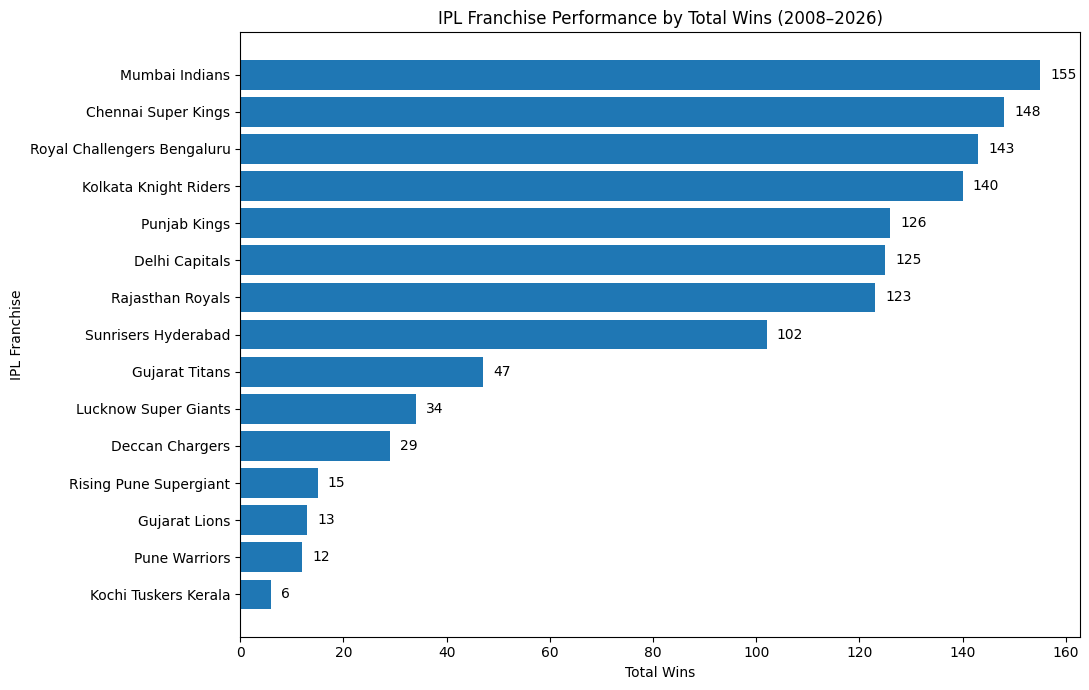

In [22]:
import matplotlib.pyplot as plt

# Sort teams by wins for the chart
chart_teams = team_performance_clean.sort_values(
    by='Wins',
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    chart_teams['Team'],
    chart_teams['Wins']
)

plt.xlabel('Total Wins')
plt.ylabel('IPL Franchise')
plt.title('IPL Franchise Performance by Total Wins (2008–2026)')

# Add win values to bars
for index, value in enumerate(chart_teams['Wins']):
    plt.text(value + 2, index, str(value), va='center')

plt.tight_layout()
plt.show()

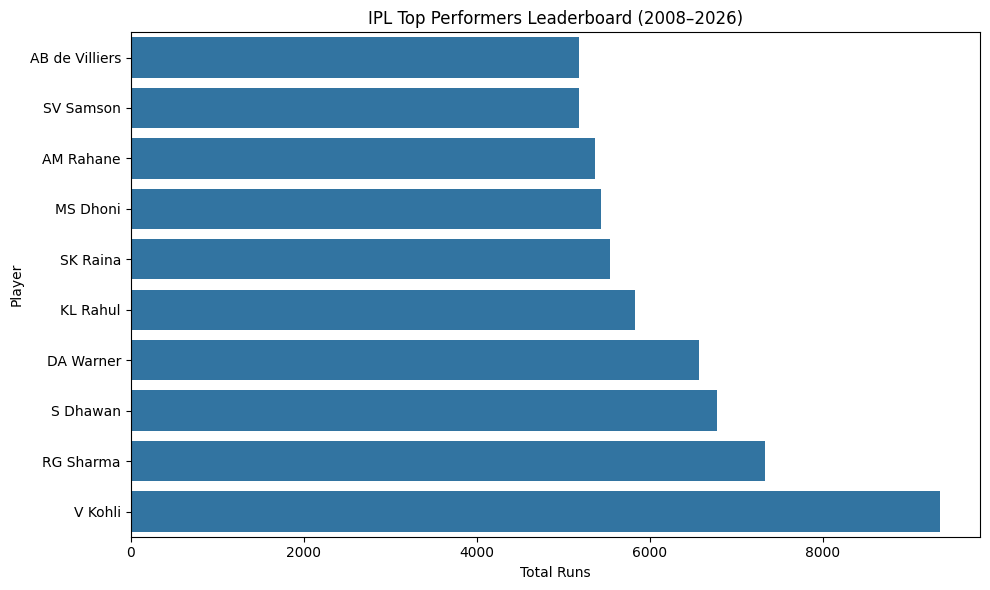

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

# Sort data for the leaderboard chart
leaderboard_data = top_10_batters.sort_values(
    by='Total_Runs',
    ascending=True
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=leaderboard_data,
    x='Total_Runs',
    y='striker'
)

plt.title('IPL Top Performers Leaderboard (2008–2026)')
plt.xlabel('Total Runs')
plt.ylabel('Player')

plt.tight_layout()
plt.show()